In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [20]:
df=pd.read_csv('/content/Data - Returning Citizen1.csv')
df

,Case Manager,Date of Enrollment,Services Requested & Offered,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,divad,1/3/23,Spoke with client who is seeking Employment Op...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,divad,1/4/23,Client reported that he is seeking job trainin...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,1/5/23,Client reported that he is seeking sober livin...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
597,NaN,1/22/24,"Senior Services, Sober Housing",NaN,NaN,NaN,NaN,NaN,1/8/24 RC came to ORC on walk in hours and rep...,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
598,NaN,1/22/24,"Mental Health or Substance Abuse Services, Sen...",NaN,NaN,NaN,NaN,NaN,1/24/24 Dir of Ops reached out to RC via phone...,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
599,NaN,1/22/24,"Job Training, Senior Services",NaN,NaN,NaN,NaN,NaN,1/18/24 RC called ORC to request housing and w...,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
600,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1/24/24 Dir of Ops reahed out to RC and no res...,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [21]:
# Rename column "Unnamed: 8" to "Service 2"
df.rename(columns={'Unnamed: 8': 'Service 2'}, inplace=True)

# Combine the values of 'Services Requested & Offered' and 'Service 2' into a new column
df['Combined Services'] = df['Services Requested & Offered'].fillna('') + df['Service 2'].fillna('')

# Select the desired columns
selected_columns = ['Case Manager', 'Date of Enrollment', 'Combined Services']

# Keep only the selected columns
df = df[selected_columns]

# Display the first few rows of the DataFrame to inspect its structure
print(df.head())

  Case Manager Date of Enrollment  \
0          NaN                NaN   
1          NaN                NaN   
2        divad             1/3/23   
3        divad             1/4/23   
4          NaN             1/5/23   

                                   Combined Services  
0                                                     
1                                                     
2  Spoke with client who is seeking Employment Op...  
3  Client reported that he is seeking job trainin...  
4  Client reported that he is seeking sober livin...  


In [23]:
df['Contains_Clothing'] = df['Combined Services'].str.contains('clothing', case=False)

# Count the number of descriptions containing the keyword 'clothing'
clothing_counts = df['Contains_Clothing'].sum()

# Output the number of descriptions containing the keyword 'clothing'
print("Number of descriptions containing the keyword 'clothing':", clothing_counts)

Number of descriptions containing the keyword 'clothing': 188


<ipython-input-23-ef42092e4f4c>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Contains_Clothing'] = df['Combined Services'].str.contains('clothing', case=False)


In [26]:
# Count the number of descriptions containing the phrase 'sober housing'
sober_housing_counts = df['Combined Services'].str.contains('sober housing', case=False).sum()

# Output the number of descriptions containing the phrase 'sober housing'
print("Number of descriptions containing the phrase 'sober housing':", sober_housing_counts)

Number of descriptions containing the phrase 'sober housing': 137


In [27]:
# Count the number of descriptions containing the phrase 'Dental'
dental_counts = df['Combined Services'].str.contains('Dental', case=False).sum()

# Output the number of descriptions containing the phrase 'Dental'
print("Number of descriptions containing the phrase 'Dental':", dental_counts)

Number of descriptions containing the phrase 'Dental': 103


In [28]:
# Count the number of descriptions containing the word 'education'
education_counts = df['Combined Services'].str.contains('Education', case=False).sum()

# Output the number of descriptions containing the word 'education'
print("Number of descriptions containing the word 'Education':", education_counts)

Number of descriptions containing the word 'Education': 126


In [29]:
# Count the number of descriptions containing the phrase 'Birth Certificate'
birth_certificate_counts = df['Combined Services'].str.contains('Birth Certificate', case=False).sum()

# Output the number of descriptions containing the phrase 'Birth Certificate'
print("Number of descriptions containing the phrase 'Birth Certificate':", birth_certificate_counts)

Number of descriptions containing the phrase 'Birth Certificate': 65


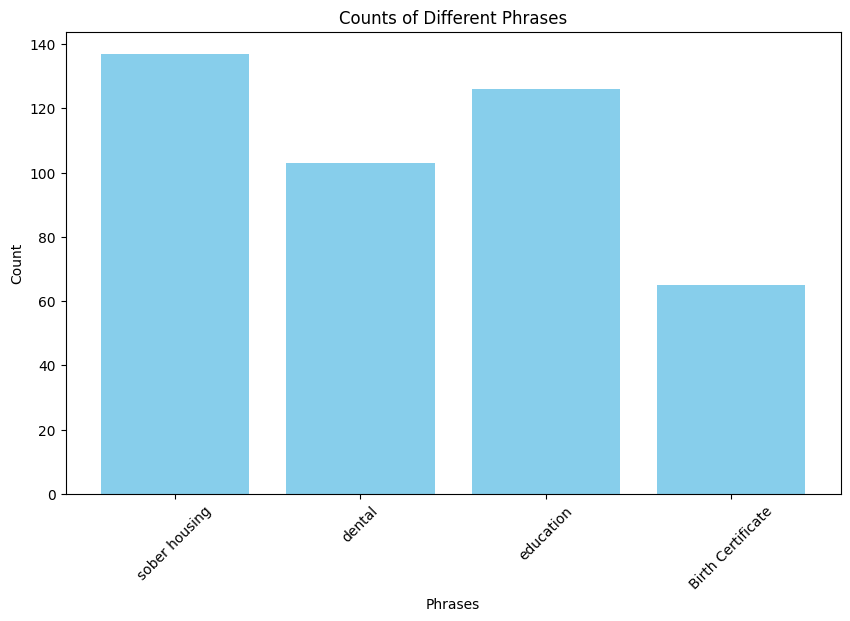

In [30]:
# Define the phrases and their counts
phrases = ['sober housing', 'dental', 'education', 'Birth Certificate']
counts = [sober_housing_counts, dental_counts, education_counts, birth_certificate_counts]

# Create a bar plot
plt.figure(figsize=(10, 6))
plt.bar(phrases, counts, color='skyblue')
plt.xlabel('Phrases')
plt.ylabel('Count')
plt.title('Counts of Different Phrases')
plt.xticks(rotation=45)
plt.show()